# FoodShock Indonesia
**Multi-Horizon Food Price & Shock Forecasting**

SDG 2.c · Machine Learning Solution Challenge 2026

Alur notebook identik dengan Streamlit. Model harga dan shock menggunakan shared functions dari `src.forecast` dan `src.train`.

## 1. Overview
Lonjakan harga pangan mengurangi keterjangkauan pangan. FoodShock memprediksi harga pangan pada bulan target dan risiko kenaikan minimal 5% terhadap bulan sebelumnya. Data WFP Indonesia 2015–2025 digunakan untuk mendukung pemantauan pasar (SDG 2.c), bukan menggantikan verifikasi harga.

Konfigurasi `REBUILD=False` membuka hasil penelitian tersimpan. Ubah ke `True` untuk melatih ulang seluruh penelitian dari raw regional.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
os.environ.setdefault('OMP_NUM_THREADS','2')
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecast import load, eligible, forecast_path, FEATURES, KEY
REBUILD = False
if REBUILD:
    from src.train import main
    main()
d, bundle = load()
print('Monthly records:',len(d),'| Markets:',d.market_id.nunique(),'| Products:',d.commodity_id.nunique())
print('Selected price model:',bundle['selected'],'| Risk model:',bundle['risk_selected'])
d[['date','province','market','commodity','unit','price']].head()

Monthly records: 327163 | Markets: 223 | Products: 29
Selected price model: Automatic (by horizon) | Risk model: Histogram Gradient Boosting


,date,province,market,commodity,unit,price
0,2015-01-01,National / unspecified,National Average,Rice,KG,12444.0
1,2015-02-01,National / unspecified,National Average,Rice,KG,12802.0
2,2015-03-01,National / unspecified,National Average,Rice,KG,13089.0
3,2015-04-01,National / unspecified,National Average,Rice,KG,12458.0
4,2015-05-01,National / unspecified,National Average,Rice,KG,12348.0


## 2. Exploratory Data Analysis
Cakupan historis tidak merata. Harga tidak dibandingkan antarproduk atau unit yang berbeda. Frekuensi shock dihitung hanya dari observasi bulanan berurutan.

,file,indonesia_rows
0,wfp_food_prices_global_2015.csv,120
1,wfp_food_prices_global_2016.csv,22768
2,wfp_food_prices_global_2017.csv,4317
3,wfp_food_prices_global_2018.csv,120
4,wfp_food_prices_global_2019.csv,120
5,wfp_food_prices_global_2020.csv,62699
6,wfp_food_prices_global_2021.csv,65352
7,wfp_food_prices_global_2022.csv,65575
8,wfp_food_prices_global_2023.csv,63486
9,wfp_food_prices_global_2024.csv,22414


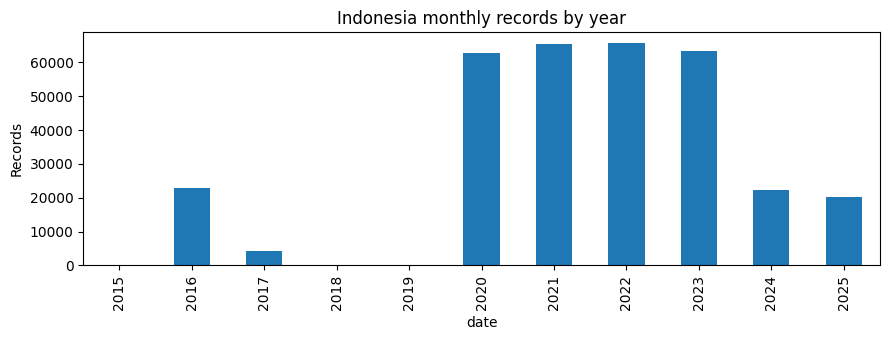

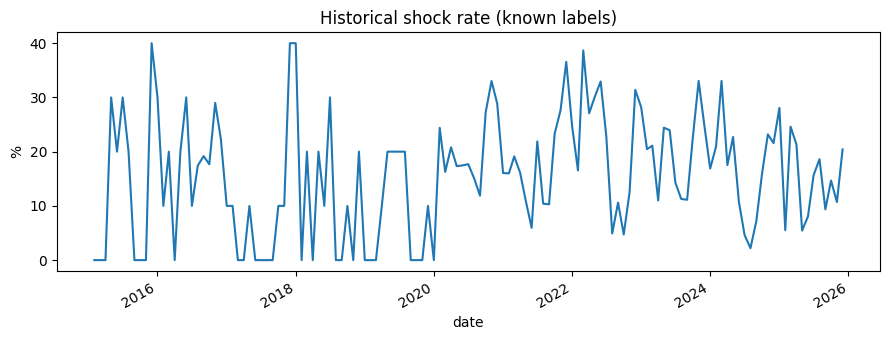

,observations
commodity,
Eggs,15578
Oil (vegetable),15558
Garlic (medium),15524
"Onions (shallot, medium)",15524
Sugar (local),15517
Rice (medium quality),15331
Meat (chicken),15261
"Meat (beef, first quality)",14225
Rice,11702


In [2]:
audit=pd.read_csv(ROOT/'data/raw/source_manifest.csv')
display(audit[['file','indonesia_rows']])
fig, ax=plt.subplots(figsize=(9,3.5));d.groupby(d.date.dt.year).size().plot.bar(ax=ax,title='Indonesia monthly records by year');ax.set_ylabel('Records');plt.tight_layout();plt.show()
known=d[d.mom1.notna()].copy();known['shock']=(known.mom1>=np.log(1.05)-1e-10).astype(int)
fig,ax=plt.subplots(figsize=(9,3.5));known.groupby('date').shock.mean().mul(100).plot(ax=ax,title='Historical shock rate (known labels)');ax.set_ylabel('%');plt.tight_layout();plt.show()
d.groupby('commodity').size().sort_values(ascending=False).head(10).to_frame('observations')

## 3. Preprocessing
Filter harga pangan retail IDR, agregasi bulanan, exact-calendar lag, volatilitas, tren, seasonality, horizon, dan missing flags. Harga hilang tidak diinterpolasi. Empat bulan berurutan diperlukan untuk origin eligible. Label shock memakai harga aktual bulan target dibanding bulan sebelumnya. Training pairs tidak melampaui cutoff label. Source lengkap: `src/forecast.py`.

In [3]:
assert not d.duplicated(KEY+['date']).any()
assert (d.price>0).all()
print('Eligible origins:',len(eligible(d)))
print('Features:',FEATURES)
display(pd.read_csv(ROOT/'results/split_audit.csv'))
d[['date','market','commodity','price','mom1','mom3','mom6','mom12','vol3','trend']].head(15)

Eligible origins: 287879
Features: ['mom1', 'mom3', 'mom6', 'mom12', 'vol3', 'trend', 'history', 'season_sin', 'season_cos', 'origin_sin', 'origin_cos', 'h', 'h2', 'trend_h', 'season_delta', 'mom6_missing', 'mom12_missing']


,phase,origin,training_pairs,evaluation_pairs
0,Validation,2020-12-01,17056,124216
1,Validation,2021-06-01,32808,97274
2,Validation,2021-12-01,49786,65543
3,Validation,2022-06-01,66462,32695
4,Retrospective test,2022-12-01,85422,104875
5,Retrospective test,2023-06-01,102656,72355
6,Retrospective test,2023-12-01,115775,41036
7,Retrospective test,2024-06-01,122754,6070
8,Deployment refit,2025-12-01,129646,0


,date,market,commodity,price,mom1,mom3,mom6,mom12,vol3,trend
0,2015-01-01,National Average,Rice,12444.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-02-01,National Average,Rice,12802.0,0.028363,NaN,NaN,NaN,NaN,NaN
2,2015-03-01,National Average,Rice,13089.0,0.022171,NaN,NaN,NaN,NaN,NaN
3,2015-04-01,National Average,Rice,12458.0,-0.049409,0.001124,NaN,NaN,0.035293,0.000375
4,2015-05-01,National Average,Rice,12348.0,-0.008869,-0.036107,NaN,NaN,0.029308,-0.012036
5,2015-06-01,National Average,Rice,12425.0,0.006216,-0.052062,NaN,NaN,0.023488,-0.017354
6,2015-07-01,National Average,Rice,12509.0,0.006738,0.004085,0.005210,NaN,0.007237,0.000868
7,2015-08-01,National Average,Rice,12709.0,0.015862,0.028816,-0.007291,NaN,0.004429,-0.001215
8,2015-09-01,National Average,Rice,12968.0,0.020174,0.042774,-0.009287,NaN,0.005601,-0.001548
9,2015-10-01,National Average,Rice,13067.0,0.007605,0.043642,0.047727,NaN,0.005215,0.007954


## 4. Training & Testing
Empat origin validasi (Des 2020, Jun 2021, Des 2021, Jun 2022; target maksimal Des 2022) untuk memilih konfigurasi dan strategi. Empat origin evaluasi retrospektif (Des 2022, Jun 2023, Des 2023, Jun 2024; target maksimal Des 2025). Model harga Ridge dan HGB dibandingkan Persistence, Seasonal Naive, dan shrinkage HGB 25/50/75%. Automatic memilih kandidat dengan MAPE validasi terbaik per kelompok horizon. Classifier HGB/Logistic dipilih menurut recall dengan FPR validasi ≤10% per kelompok. Deployment refit menggunakan label sampai 2025 serta kuantil error dan ambang dari prediksi historis out-of-fold hingga 2025. Ini bukan kalibrasi terpisah dari model refit dan tidak memiliki test independen setelah 2025.

,phase,model,horizon,n,MAPE,RMSLE
0,Validation pooled,Persistence,All,319728,15.515351,0.253851
10,Validation pooled,Seasonal Naive,All,319728,16.878586,0.307659
20,Validation pooled,Ridge,All,319728,19.140618,0.275615
30,Validation pooled,Histogram Gradient Boosting,All,319728,16.570788,0.260241
40,Validation pooled,HGB blend 25%,All,319728,15.309586,0.249940
50,Validation pooled,HGB blend 50%,All,319728,15.440245,0.249722
60,Validation pooled,HGB blend 75%,All,319728,15.863268,0.253205
70,Validation pooled,Automatic (by horizon),All,319728,14.652078,0.252991
80,Test 2023–2025,Persistence,All,224336,12.634742,0.206102
91,Test 2023–2025,Seasonal Naive,All,224336,16.598904,0.245806


,phase,model,horizon,n,MAPE,RMSLE
157,Test 2023–2025,Automatic (by horizon),All,224336,13.683753,0.214167
158,Test 2023–2025,Automatic (by horizon),1,16065,5.864811,0.099533
159,Test 2023–2025,Automatic (by horizon),3,12200,11.319446,0.181690
160,Test 2023–2025,Automatic (by horizon),6,12503,21.955809,0.320815
161,Test 2023–2025,Automatic (by horizon),12,8687,13.899283,0.261139
162,Test 2023–2025,Automatic (by horizon),24,4874,12.279992,0.177053
163,Test 2023–2025,Automatic (by horizon),36,1638,15.269690,0.213568
164,Test 2023–2025,Automatic (by horizon),1–3,40626,8.309459,0.141344
165,Test 2023–2025,Automatic (by horizon),4–6,37033,17.206168,0.266339
166,Test 2023–2025,Automatic (by horizon),7–12,54726,16.349604,0.254408


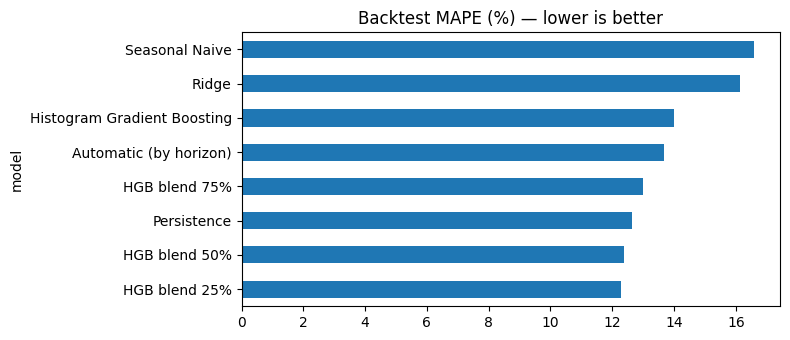

,phase,model,horizon,n,threshold,AP,AUC,precision,recall,F1,FPR,TP,FP,FN,TN,prevalence
0,Validation pooled,Logistic Regression,All,319650,NaN,0.266913,0.586632,0.340866,0.205164,0.256152,0.099957,13198,25521,51131,229800,0.201248
10,Validation pooled,Histogram Gradient Boosting,All,319650,NaN,0.348223,0.699066,0.424185,0.289496,0.344131,0.099013,18623,25280,45706,230041,0.201248
20,Test 2023–2025,Logistic Regression,All,217627,NaN,0.301636,0.684459,0.282439,0.312002,0.296486,0.169301,11950,30360,26351,148966,0.175994
31,Test 2023–2025,Histogram Gradient Boosting,All,217627,NaN,0.319134,0.701191,0.383264,0.222187,0.281299,0.076364,8510,13694,29791,165632,0.175994


,Predicted non-shock,Predicted shock
Actual non-shock,165632,13694
Actual shock,29791,8510


,model,horizon,n,coverage,log_error_q10,log_error_q90
0,Persistence,1–3,40626,0.816448,-0.200931,0.116588
1,Persistence,4–6,37033,0.822132,-0.318050,0.201410
2,Persistence,7–12,54726,0.863356,-0.229501,0.314840
3,Persistence,13–36,91951,0.879218,-0.131736,0.387601
4,Seasonal Naive,1–3,40626,0.804460,-0.158662,0.363386
5,Seasonal Naive,4–6,37033,0.822618,-0.204911,0.366671
6,Seasonal Naive,7–12,54726,0.819610,-0.147004,0.361433
7,Seasonal Naive,13–36,91951,0.908756,-0.125163,0.551245
8,Ridge,1–3,40626,0.809014,-0.204901,0.174547
9,Ridge,4–6,37033,0.797937,-0.278571,0.238033


Deployment Policy


,horizon,validation_threshold,deployment_oof_threshold,price_model,validation_n,deployment_oof_n
0,1–3,0.406070,0.419511,HGB blend 25%,64605,105231
1,4–6,0.468577,0.456056,Seasonal Naive,64553,101586
2,7–12,0.422127,0.400715,Seasonal Naive,96215,150941
3,13–36,0.398056,0.372592,HGB blend 25%,94355,186306


Tuning Price


... (11 outputs left out)

Importance


,feature,AP_drop,std
0,season_cos,0.158751,0.003670
1,vol3,0.106283,0.007052
2,mom1,0.007953,0.003907
3,mom6,0.007575,0.002242
4,trend_h,0.003981,0.000338
5,season_delta,0.002263,0.000144
6,history,0.001174,0.003022
7,mom12_missing,0.000183,0.000303
8,origin_sin,0.000000,0.000000
9,origin_cos,0.000000,0.000000


Segment Metrics


,segment,value,n,MAPE,precision,recall,FPR,AP
0,commodity,Chili (bird's eye),5007,32.736457,0.300529,0.381124,0.576601,0.374015
1,commodity,"Chili (bird's eye, green)",4574,30.297978,0.297925,0.381163,0.484157,0.344924
2,commodity,"Chili (bird's eye, red)",4239,38.569542,0.327231,0.402817,0.617128,0.424931
3,commodity,Chili (red),5007,35.019640,0.431299,0.432306,0.439209,0.419792
4,commodity,"Chili (red, curly)",1206,32.994225,0.454545,0.788337,0.590296,0.386449
5,commodity,"Chili (red, large)",3912,35.414561,0.448029,0.435540,0.437707,0.451290
6,commodity,Eggs,17521,7.225186,0.234270,0.074627,0.039448,0.187409
7,commodity,Eggs (broiler),5031,6.756043,0.255906,0.106209,0.043609,0.230669
8,commodity,Garlic,5007,21.650023,0.586111,0.121544,0.046767,0.514104
9,commodity,Garlic (medium),17545,18.972847,0.332370,0.102617,0.051307,0.298258


In [4]:
metrics=pd.read_csv(ROOT/'results/forecast_metrics.csv');risk=pd.read_csv(ROOT/'results/shock_metrics.csv')
MODEL=bundle['selected']  # Automatic (by horizon), atau model harga tertentu
test=metrics[metrics.phase.str.startswith('Test')]
display(metrics[metrics.horizon.astype(str)=='All'])
display(test[test.model.eq(MODEL)])
fig,ax=plt.subplots(figsize=(8,3.5));test[test.horizon.astype(str)=='All'].set_index('model').MAPE.sort_values().plot.barh(ax=ax,title='Backtest MAPE (%) — lower is better');plt.tight_layout();plt.show()
display(risk[risk.horizon.astype(str)=='All'])
q=risk[risk.phase.str.startswith('Test') & risk.model.eq(bundle['risk_selected']) & risk.horizon.astype(str).eq('All')].iloc[0]
display(pd.DataFrame([[q.TN,q.FP],[q.FN,q.TP]],index=['Actual non-shock','Actual shock'],columns=['Predicted non-shock','Predicted shock']).astype(int))
display(pd.read_csv(ROOT/'results/interval_coverage.csv'))
for name in ['deployment_policy','tuning_price','tuning_risk','ablation','sampling_sensitivity','rolling_origin','rolling_risk','importance','segment_metrics']:
    print(name.replace('_',' ').title());display(pd.read_csv(ROOT/f'results/{name}.csv').head(20))


**Interpretasi:** model dan threshold dipilih dari validasi, bukan performa retrospektif. Bandingkan kandidat secara jujur dengan Persistence. Performa berbeda menurut horizon; agregat rolling-origin menghitung setiap pasangan origin–target, termasuk target yang berulang. Data 2023–2025 sudah dilihat dalam versi proyek sebelumnya; evaluasi bukan test baru yang sepenuhnya untouched.

## 5. Prediction
Masukkan target tanggal, bukan tanggal acuan. Data bulanan: semua tanggal dalam bulan sama menghasilkan prediksi sama. `SERIES_ID` dipilih dari daftar pasar–produk dengan origin layak tahun 2025. Hasil menggunakan engine yang sama dengan Streamlit. Horizon di atas 36 bulan ditandai ekstrapolasi (tanpa risk score ML).

,series,province,market,commodity,unit,date
6675,111,ACEH,Pasar Inpres,Eggs,KG,2025-12-01
7629,128,ACEH,Pasar Inpres,Garlic (medium),KG,2025-12-01
7135,118,ACEH,Pasar Inpres,"Meat (beef, first quality)",KG,2025-12-01
6751,112,ACEH,Pasar Inpres,Meat (chicken),KG,2025-12-01
6827,113,ACEH,Pasar Inpres,Oil (vegetable),KG,2025-12-01
7975,134,ACEH,Pasar Inpres,"Onions (shallot, medium)",KG,2025-12-01
7705,129,ACEH,Pasar Inpres,Rice (medium quality),KG,2025-12-01
7781,130,ACEH,Pasar Inpres,Sugar (local),KG,2025-12-01
8227,138,ACEH,Pasar Kota Lhokseumawe,Eggs,KG,2025-12-01
9184,155,ACEH,Pasar Kota Lhokseumawe,Garlic (medium),KG,2025-12-01


Pasar Mundu | Rice (medium quality) | KG | origin 2025-12
Target: 2028-01 | Horizon: 25 bulan
Predicted price: Rp15,528 | Change: +0.11% | Risk score: 0.060
Price model: HGB blend 25% | Risk threshold: 0.37259234493292426
Classification: NON-SHOCK


,lower,upper,date,horizon,price,change,risk_score,threshold,shock,price_implied_shock,price_model,extrapolation
19,13569.400709,21135.998488,2027-08-01,20,15378.421240,-0.001326,0.036956,0.372592,False,False,HGB blend 25%,False
20,13606.549461,21193.862206,2027-09-01,21,15420.522521,0.002738,0.057377,0.372592,False,False,HGB blend 25%,False
21,13606.549461,21193.862206,2027-10-01,22,15420.522521,0.000000,0.056478,0.372592,False,False,HGB blend 25%,False
22,13630.289870,21230.840792,2027-11-01,23,15447.427911,0.001745,0.060945,0.372592,False,False,HGB blend 25%,False
23,13686.396694,21318.234021,2027-12-01,24,15511.014682,0.004116,0.060142,0.372592,False,False,HGB blend 25%,False
24,13701.644969,21341.985071,2028-01-01,25,15528.295798,0.001114,0.060242,0.372592,False,False,HGB blend 25%,False


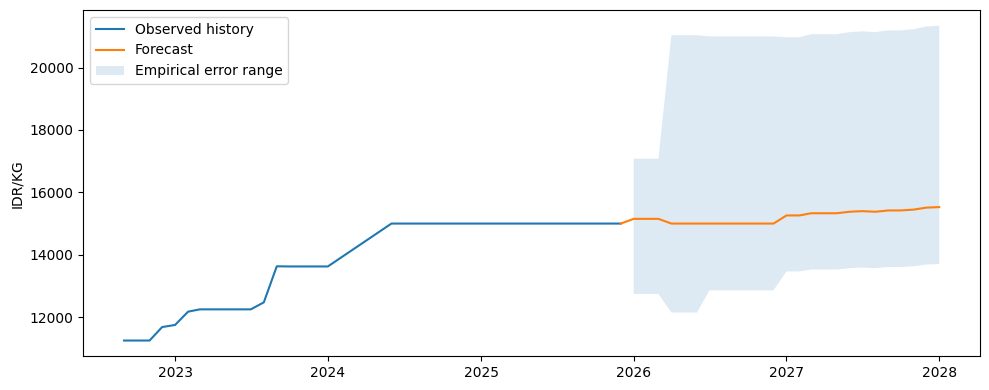

In [5]:
latest=eligible(d).sort_values('date').groupby('series',as_index=False).tail(1)
choices=latest[latest.date.dt.year.eq(2025)][['series','province','market','commodity','unit','date']].sort_values(['province','market','commodity'])
display(choices.head(15))
TARGET_DATE='2028-01-31'
SERIES_ID=868  # Pasar Mundu, Rice (medium quality), KG
ALGORITHM=None  # None = Automatic by horizon; atau 'Ridge'
origin,path=forecast_path(d,SERIES_ID,TARGET_DATE,bundle,ALGORITHM)
print(f'{origin.market} | {origin.commodity} | {origin.unit} | origin {origin.date:%Y-%m}')
r=path.iloc[-1]
print('Target:',r.date.strftime('%Y-%m'),'| Horizon:',r.horizon,'bulan')
print(f'Predicted price: Rp{r.price:,.0f} | Change: {r.change:+.2%} | Risk score: {r.risk_score:.3f}')
print('Price model:', r.price_model, '| Risk threshold:', r.threshold)
print('Classification:', 'Extrapolation (price-implied shock only)' if r.extrapolation else ('SHOCK' if r.shock else 'NON-SHOCK'))
display(path.tail(6))
hist=d[d.series.eq(SERIES_ID)&d.date.le(origin.date)].sort_values('date').tail(36)
fig,ax=plt.subplots(figsize=(10,4));ax.plot(hist.date,hist.price,label='Observed history');ax.plot(pd.concat([pd.Series([origin.date]),path.date],ignore_index=True),np.r_[origin.price,path.price],label='Forecast');ax.fill_between(path.date,path.lower,path.upper,alpha=.15,label='Empirical error range');ax.set_ylabel(f'IDR/{origin.unit}');ax.legend();plt.tight_layout();plt.show()

### Limitations
Harga dan risk score masa depan bersifat kondisional. Tidak ada data pasokan, cuaca, atau kebijakan setelah 2025. Rentang empiris bukan jaminan cakupan; deployment memakai kuantil OOF kelompok 13–36; validasi awal hanya mencapai 24 bulan. Untuk target lebih jauh dari 36 bulan, hanya ekstrapolasi musiman dengan tren teredam yang disediakan. Lihat README untuk sumber data, instruksi reproduksi, dan seluruh keterbatasan.

**References:** [Kaggle WFP dataset](https://www.kaggle.com/datasets/abhishekgupta56447/global-food-prices-database-wfp); [UN SDG 2](https://sdgs.un.org/goals/goal2).